# DSC8307 Data Mining, Modeling and Analytics

**Student:** Joshua Micaiah Opaman  
**Programme:** Master of Science in Data Science and Analytics  
**Course:** DSC8307  


# Project 1: Bank Marketing

## 1. Problem formulation

The operational objective is to rank customers before calls are made, so that limited calling capacity is directed toward customers with higher subscription probability. The target is **y** (term-deposit subscription). This is an imbalanced binary classification problem.

**Key design decision:** `duration` is unavailable before a call finishes and strongly determines the outcome. It is therefore excluded from the deployable model to avoid target leakage. A separate benchmark including duration is reported only to quantify how misleadingly optimistic post-call performance can be.

In [1]:
import warnings, sys, platform, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
 roc_auc_score, average_precision_score, confusion_matrix, classification_report, RocCurveDisplay,
 PrecisionRecallDisplay, brier_score_loss)
from sklearn.calibration import CalibrationDisplay
RANDOM_STATE=42
print('Python',sys.version.split()[0], '| pandas',pd.__version__)

Python 3.13.5 | pandas 2.2.3


## 2. Data loading, structure, quality and exploratory analysis

In [2]:
df=pd.read_csv('bank-additional-full.csv',sep=';')
print('Shape:',df.shape)
display(df.head())
display(pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique()}))

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,dtype,missing,unique
age,int64,0,78
job,object,0,12
marital,object,0,4
education,object,0,8
default,object,0,3
housing,object,0,3
loan,object,0,3
contact,object,0,2
month,object,0,10
day_of_week,object,0,5


In [3]:
target=(df.y=='yes').astype(int)
print(df.y.value_counts())
print('Subscription rate: {:.2%}'.format(target.mean()))
unknown=pd.Series({c:(df[c].astype(str)=='unknown').mean() for c in df.select_dtypes('object') if c!='y'}).sort_values(ascending=False)
display(unknown.to_frame('unknown_rate'))
print('Duplicate rows:',df.duplicated().sum())

y
no     36548
yes     4640
Name: count, dtype: int64
Subscription rate: 11.27%


,unknown_rate
default,0.208726
education,0.042027
housing,0.024036
loan,0.024036
job,0.008012
marital,0.001942
contact,0.000000
month,0.000000
day_of_week,0.000000
poutcome,0.000000


Duplicate rows: 12


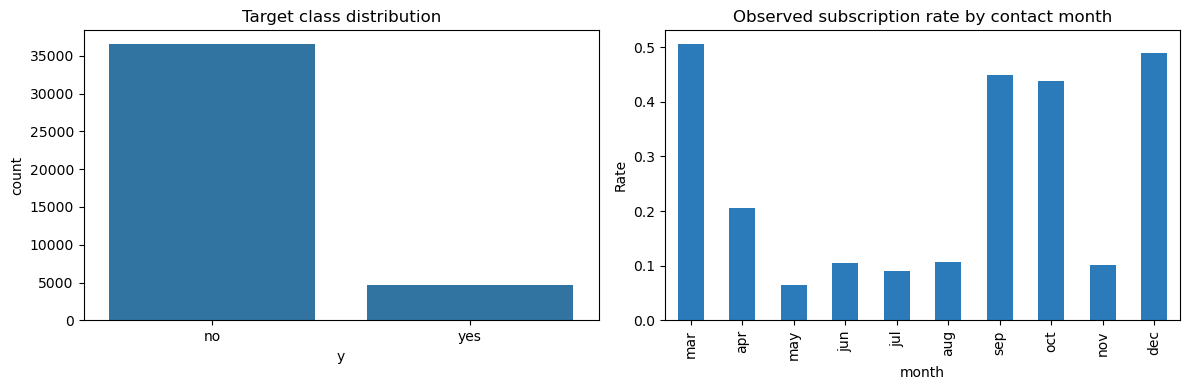

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024,10.421,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285,259.279,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.568,2.770,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475,186.911,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.173,0.495,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.082,1.571,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.576,0.579,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621,1.734,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.036,72.252,4963.600,5099.100,5191.000,5228.100,5228.100


In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=df,x='y',ax=ax[0]); ax[0].set_title('Target class distribution')
monthly=pd.crosstab(df.month,df.y,normalize='index').reindex(['mar','apr','may','jun','jul','aug','sep','oct','nov','dec'])
monthly['yes'].plot(kind='bar',ax=ax[1],color='#2b7bba'); ax[1].set_title('Observed subscription rate by contact month'); ax[1].set_ylabel('Rate')
plt.tight_layout(); plt.show()
num=df.select_dtypes(include=np.number)
display(num.describe().T.round(3))

### Preparation justification
- Native nulls are checked separately from the dataset's explicit `unknown` category. `unknown` is retained because it may carry operational information and indiscriminate row deletion would reduce representativeness.
- `pdays=999` means not previously contacted, not an extreme number of days. A binary indicator is created and `pdays` is set to missing for those customers, allowing imputation without treating 999 as continuous distance.
- Categorical variables are one-hot encoded for logistic regression. Numeric variables are median-imputed and standardized.
- The test set is stratified and held out once for final comparison. Five-fold stratified cross-validation on the training set assesses stability.

In [5]:
data=df.copy()
data['previously_contacted']=(data.pdays!=999).astype(int)
data.loc[data.pdays==999,'pdays']=np.nan
X=data.drop(columns=['y','duration'])
y=(data.y=='yes').astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=RANDOM_STATE)
print('Train:',X_train.shape,'Test:',X_test.shape,'Train positive:',y_train.mean().round(4),'Test positive:',y_test.mean().round(4))
majority=np.zeros_like(y_test)
print('Majority baseline accuracy:',accuracy_score(y_test,majority))
print('Majority baseline balanced accuracy:',balanced_accuracy_score(y_test,majority))
print('Majority baseline recall:',recall_score(y_test,majority,zero_division=0))

Train: (32950, 20) Test: (8238, 20) Train positive: 0.1127 Test positive: 0.1126
Majority baseline accuracy: 0.8873512988589464
Majority baseline balanced accuracy: 0.5
Majority baseline recall: 0.0


## 3. Candidate models and ranking rationale

1. **Histogram Gradient Boosting:** primary non-linear candidate; captures interactions and thresholds while remaining efficient.
2. **Random Forest:** robust ensemble benchmark with non-linear interactions and low preprocessing sensitivity.
3. **Regularized Logistic Regression:** transparent, strong linear baseline with probabilistic output.

Ranking is based primarily on **average precision (PR-AUC)** because the positive class is rare, then ROC-AUC, recall, calibration and cross-validation variability. Accuracy is reported but not used alone.

In [6]:
cat=X_train.select_dtypes(include='object').columns.tolist(); num=[c for c in X_train.columns if c not in cat]
linear_pre=ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler())]),num),('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore'))]),cat)])
ordinal_pre=ColumnTransformer([('num',SimpleImputer(strategy='median'),num),('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('ord',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1))]),cat)])
models={
 'Logistic regression':Pipeline([('pre',linear_pre),('model',LogisticRegression(max_iter=1500,class_weight='balanced',C=1.0))]),
 'Random forest':Pipeline([('pre',ordinal_pre),('model',RandomForestClassifier(n_estimators=350,min_samples_leaf=8,class_weight='balanced_subsample',n_jobs=-1,random_state=RANDOM_STATE))]),
 'Histogram gradient boosting':Pipeline([('pre',ordinal_pre),('model',HistGradientBoostingClassifier(max_iter=250,learning_rate=.06,max_leaf_nodes=31,l2_regularization=1.0,random_state=RANDOM_STATE))])}
cv=StratifiedKFold(5,shuffle=True,random_state=RANDOM_STATE)
scoring={'roc_auc':'roc_auc','pr_auc':'average_precision','balanced_accuracy':'balanced_accuracy','f1':'f1'}
rows=[]
for name,m in models.items():
    r=cross_validate(m,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
    rows.append({'model':name,**{k.replace('test_','')+'_mean':v.mean() for k,v in r.items() if k.startswith('test_')},**{k.replace('test_','')+'_sd':v.std() for k,v in r.items() if k.startswith('test_')}})
cvres=pd.DataFrame(rows).sort_values('pr_auc_mean',ascending=False)
display(cvres.round(4))

,model,roc_auc_mean,pr_auc_mean,balanced_accuracy_mean,f1_mean,roc_auc_sd,pr_auc_sd,balanced_accuracy_sd,f1_sd
1,Random forest,0.7909,0.4675,0.7454,0.4927,0.0042,0.0102,0.0055,0.0062
2,Histogram gradient boosting,0.7992,0.4668,0.6173,0.3628,0.0035,0.0131,0.0074,0.0163
0,Logistic regression,0.7896,0.4435,0.7380,0.4483,0.0055,0.0086,0.0015,0.0037


In [7]:
test_rows=[]; fitted={}
for name,m in models.items():
    m.fit(X_train,y_train); fitted[name]=m
    p=m.predict_proba(X_test)[:,1]; pred=(p>=.5).astype(int)
    test_rows.append({'model':name,'ROC-AUC':roc_auc_score(y_test,p),'PR-AUC':average_precision_score(y_test,p),'Brier':brier_score_loss(y_test,p),'Balanced accuracy':balanced_accuracy_score(y_test,pred),'Precision@.5':precision_score(y_test,pred,zero_division=0),'Recall@.5':recall_score(y_test,pred),'F1@.5':f1_score(y_test,pred)})
testres=pd.DataFrame(test_rows).sort_values('PR-AUC',ascending=False); display(testres.round(4))
best_name=testres.iloc[0]['model']; best=fitted[best_name]; best_p=best.predict_proba(X_test)[:,1]
print('Selected model:',best_name)

  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.

,model,ROC-AUC,PR-AUC,Brier,Balanced accuracy,Precision@.5,Recall@.5,F1@.5
2,Histogram gradient boosting,0.8182,0.4988,0.0741,0.6216,0.6818,0.2586,0.3750
1,Random forest,0.8097,0.4960,0.1137,0.7629,0.4468,0.6239,0.5207
0,Logistic regression,0.8009,0.4602,0.1616,0.7523,0.3677,0.6455,0.4685


Selected model: Histogram gradient boosting


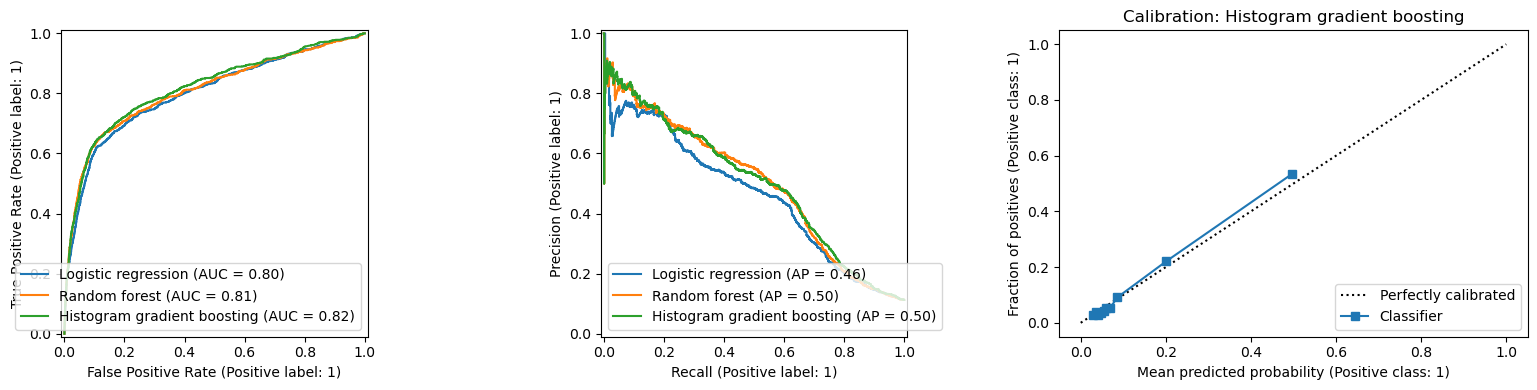

In [8]:
fig,ax=plt.subplots(1,3,figsize=(16,4))
for name,m in fitted.items():
 p=m.predict_proba(X_test)[:,1]; RocCurveDisplay.from_predictions(y_test,p,name=name,ax=ax[0]); PrecisionRecallDisplay.from_predictions(y_test,p,name=name,ax=ax[1])
CalibrationDisplay.from_predictions(y_test,best_p,n_bins=10,strategy='quantile',ax=ax[2]); ax[2].set_title('Calibration: '+best_name)
plt.tight_layout(); plt.show()

## 4. Decision threshold: unnecessary calls versus missed subscribers

A 0.50 threshold is not automatically optimal. Here a practical threshold is selected by maximizing F2, which weights recall twice as heavily as precision. A capacity table also shows the outcome if the bank calls only the highest-scoring 5%, 10%, 20% or 30%. This makes the recommendation auditable and allows management to substitute its actual call capacity or economic costs.

In [9]:
thresholds=np.linspace(.02,.80,157); tr=[]
for t in thresholds:
 pred=(best_p>=t).astype(int); tn,fp,fn,tp=confusion_matrix(y_test,pred).ravel()
 prec=precision_score(y_test,pred,zero_division=0); rec=recall_score(y_test,pred)
 f2=(5*prec*rec/(4*prec+rec)) if (4*prec+rec)>0 else 0
 tr.append([t,tp,fp,fn,tn,prec,rec,f2,pred.mean()])
thr=pd.DataFrame(tr,columns=['threshold','TP','FP','FN','TN','precision','recall','F2','call_rate'])
recommended=thr.loc[thr.F2.idxmax()]
display(recommended.to_frame('recommended').round(4))
# Sensitivity around recommendation
display(thr.iloc[(thr.threshold-recommended.threshold).abs().argsort()[:7]].sort_values('threshold').round(4))
# Capacity analysis
cap=[]
order=np.argsort(-best_p)
for rate in [.05,.10,.20,.30]:
 n=int(np.ceil(rate*len(y_test))); chosen=order[:n]
 cap.append({'call_top_%':int(rate*100),'customers_called':n,'subscribers_found':int(y_test.iloc[chosen].sum()),'precision':y_test.iloc[chosen].mean(),'recall_of_all_subscribers':y_test.iloc[chosen].sum()/y_test.sum(),'lift_vs_random':y_test.iloc[chosen].mean()/y_test.mean()})
display(pd.DataFrame(cap).round(3))

,recommended
threshold,0.1250
TP,607.0000
FP,858.0000
FN,321.0000
TN,6452.0000
precision,0.4143
recall,0.6541
F2,0.5862
call_rate,0.1778


,threshold,TP,FP,FN,TN,precision,recall,F2,call_rate
18,0.110,620,992,308,6318,0.3846,0.6681,0.5823,0.1957
19,0.115,612,935,316,6375,0.3956,0.6595,0.5819,0.1878
20,0.120,607,893,321,6417,0.4047,0.6541,0.5823,0.1821
21,0.125,607,858,321,6452,0.4143,0.6541,0.5862,0.1778
22,0.130,601,813,327,6497,0.4250,0.6476,0.5862,0.1716
23,0.135,596,781,332,6529,0.4328,0.6422,0.5856,0.1672
24,0.140,593,759,335,6551,0.4386,0.6390,0.5855,0.1641


,call_top_%,customers_called,subscribers_found,precision,recall_of_all_subscribers,lift_vs_random
0,5,412,273,0.663,0.294,5.882
1,10,824,441,0.535,0.475,4.751
2,20,1648,623,0.378,0.671,3.356
3,30,2472,698,0.282,0.752,2.507


Recommended threshold: 0.125
                 precision    recall  f1-score   support

No subscription       0.95      0.88      0.92      7310
   Subscription       0.41      0.65      0.51       928

       accuracy                           0.86      8238
      macro avg       0.68      0.77      0.71      8238
   weighted avg       0.89      0.86      0.87      8238



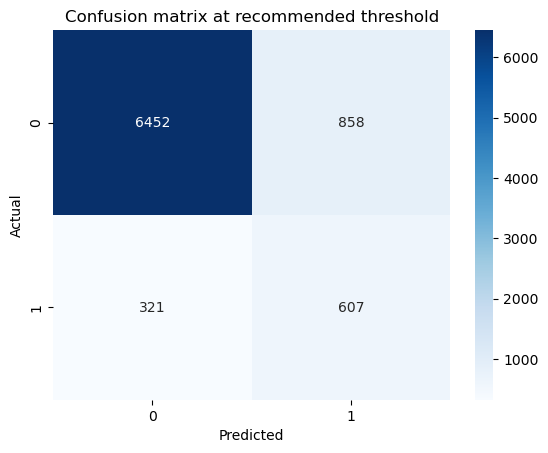

In [10]:
t=float(recommended.threshold); pred=(best_p>=t).astype(int)
print('Recommended threshold:',round(t,3))
print(classification_report(y_test,pred,target_names=['No subscription','Subscription']))
cm=confusion_matrix(y_test,pred); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues'); plt.xlabel('Predicted');plt.ylabel('Actual');plt.title('Confusion matrix at recommended threshold');plt.show()

### Threshold interpretation
The F2 threshold is a defensible starting point when missing a genuine subscriber is considered substantially more costly than making an extra call. Lowering it increases recall but produces more false-positive calls; raising it reduces call volume and usually raises precision, but misses more subscribers. Final deployment should use the bank's actual expected profit per subscription, cost per call, contact capacity and customer-contact policy. The capacity table is preferable where a fixed number of calls can be made.

## 5. Leakage sensitivity: what happens if duration is included?

In [11]:
# Benchmark only: add duration back and use logistic regression
X_leak=data.drop(columns='y'); Xl_tr,Xl_te,yl_tr,yl_te=train_test_split(X_leak,y,test_size=.20,stratify=y,random_state=RANDOM_STATE)
catl=Xl_tr.select_dtypes('object').columns.tolist(); numl=[c for c in Xl_tr.columns if c not in catl]
prel=ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler())]),numl),('cat',OneHotEncoder(handle_unknown='ignore'),catl)])
leak=Pipeline([('pre',prel),('model',LogisticRegression(max_iter=1500,class_weight='balanced'))]).fit(Xl_tr,yl_tr)
pl=leak.predict_proba(Xl_te)[:,1]
print({'deployable_best_ROC_AUC':round(roc_auc_score(y_test,best_p),4),'with_duration_ROC_AUC':round(roc_auc_score(yl_te,pl),4),'deployable_best_PR_AUC':round(average_precision_score(y_test,best_p),4),'with_duration_PR_AUC':round(average_precision_score(yl_te,pl),4)})

{'deployable_best_ROC_AUC': np.float64(0.8182), 'with_duration_ROC_AUC': np.float64(0.9439), 'deployable_best_PR_AUC': np.float64(0.4988), 'with_duration_PR_AUC': np.float64(0.6226)}


## 6. Conclusions, limitations and responsible recommendation

- The majority baseline is deceptively strong on accuracy because non-subscribers dominate, but it has zero subscriber recall. PR-AUC, recall, precision, balanced accuracy and calibration are therefore essential.
- The best model is selected using cross-validation and verified on a held-out test set. Differences should be interpreted together with fold variability, not from a single metric alone.
- `duration` is excluded from the actionable model. Including it answers a post-call rather than pre-call question.
- Observed associations do not establish that changing age, contact month or any other attribute will cause subscription. The model supports prioritization, not causal policy.
- Before production, validate on a later campaign period, monitor subgroup performance and calibration, record contact costs and outcomes, and retrain when drift is material. Customer privacy, fair-treatment and opt-out rules should constrain use.

**Recommendation:** use the selected deployable model to rank customers, begin with the reported F2 threshold or a fixed top-capacity segment, and conduct a controlled prospective pilot. Compare conversion, calls per subscriber, opt-outs and complaints against business-as-usual before scaling.